In [1]:
import h5pyd
import h5py
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime
import geopandas as gpd
from matplotlib_scalebar.scalebar import ScaleBar

In [2]:
sites = pd.read_csv('C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Data/MasterSiteList_FollowupPaper.csv')
sites = sites.iloc[0:15,0:8]

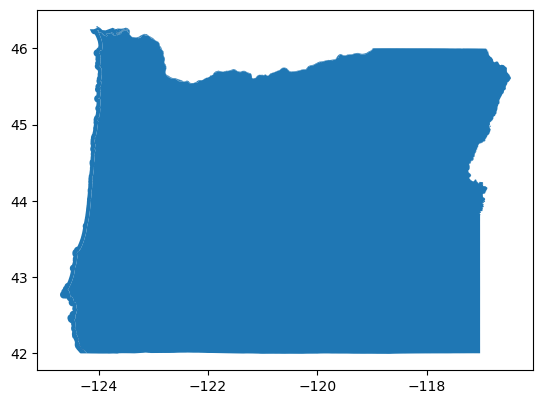

In [3]:
#oregon outline
oregon = gpd.read_file('C:/Users/sarah/Desktop/ORKA/GISResources/OregonState_Shapefile_HigherRes/Oregon_State_Boundary.shp')
or_trans = oregon.to_crs("EPSG:4326")
or_trans.plot()
or_sea = or_trans.loc[or_trans.FEATURE == 0].reset_index()
or_land = or_trans.loc[or_trans.FEATURE == 3].reset_index()
#for reference, can plot it using this: or_sea.plot(ax = ax1, color = "blue")

In [4]:
#8 - 9 minutes
#Has 46007 unique lat/lon combos over 4256 time steps. About 40 mil rows dropped with dropna()
#temp = pd.read_csv("D:/ORKA_StatusReportFollowupPaper/LO_SurfaceBrookingsAreas/processed_yearlyfiles/surface_temp_all_combined.csv")
#Combine the two datasets together
#temp is 235,526,278 rows long
temp = pd.read_csv("D:/ORKA_StatusReportFollowupPaper/LO_SurfaceBrookingsAreas/processed_yearlyfiles/surface_temp_all.csv")
temp = temp.dropna()
#temp_east is 10,733,967 rows long
temp_east = pd.read_csv("D:/ORKA_StatusReportFollowupPaper/LO_SurfaceBrookingsAreas/processed_yearlyfiles/surface_temp_east_all.csv")
temp = pd.concat([temp,temp_east])
print("Number of time steps is", temp.ocean_time.nunique())
print("Lat/lon combos is", len(temp[['lon_rho','lat_rho']].drop_duplicates()))
#drop 2024 values and reset index
temp.ocean_time = pd.to_datetime(temp.ocean_time)
temp = temp.loc[temp.ocean_time < "2023-12-31"].reset_index()

Number of time steps is 4383
Lat/lon combos is 48278


In [5]:
temp.lon_rho.max()

-123.50325326607414

In [5]:
#Looking at offshore to nearshore gradients in our regions and if exposure to warm temps increases
temp_pa = temp.loc[(temp.lat_rho.between(45.15, 45.27)) & (temp.lon_rho.between(-124.3,-123.9))].reset_index()
temp_pa_p90 = temp_pa.groupby(["lon_rho","lat_rho"]).surf_temp.quantile(0.9).reset_index()

temp_fo = temp.loc[(temp.lat_rho.between(44.73, 44.82)) & (temp.lon_rho.between(-124.38,-124.05))].reset_index()
temp_fo_p90 = temp_fo.groupby(["lon_rho","lat_rho"]).surf_temp.quantile(0.9).reset_index()

temp_ca = temp.loc[(temp.lat_rho.between(43.25, 43.37)) & (temp.lon_rho.between(-124.66,-124.32))].reset_index()
temp_ca_p90 = temp_ca.groupby(["lon_rho","lat_rho"]).surf_temp.quantile(0.9).reset_index()

temp_po = temp.loc[(temp.lat_rho.between(42.6, 42.85)) & (temp.lon_rho.between(-124.83,-124.4))].reset_index()
temp_po_p90 = temp_po.groupby(["lon_rho","lat_rho"]).surf_temp.quantile(0.9).reset_index()
temp_ro = temp.loc[(temp.lat_rho.between(42.4, 42.52)) & (temp.lon_rho.between(-124.72,-124.42))].reset_index()
temp_ro_p90 = temp_ro.groupby(["lon_rho","lat_rho"]).surf_temp.quantile(0.9).reset_index()
temp_br = temp.loc[(temp.lat_rho.between(42.01, 42.1)) & (temp.lon_rho.between(-124.6,-124.2))].reset_index()
temp_br_p90 = temp_br.groupby(["lon_rho","lat_rho"]).surf_temp.quantile(0.9).reset_index()

In [7]:
temp_pa

,level_0,index,ocean_time,eta_rho,xi_rho,surf_temp,lon_rho,lat_rho,Unnamed: 0
0,26125,35410,2013-01-01 12:00:00,302,76,10.553284,-124.294192,45.151088,NaN
1,26126,35411,2013-01-01 12:00:00,302,77,10.537955,-124.286294,45.151088,NaN
2,26127,35412,2013-01-01 12:00:00,302,78,10.532032,-124.278427,45.151088,NaN
3,26128,35413,2013-01-01 12:00:00,302,79,10.523454,-124.270592,45.151088,NaN
4,26129,35414,2013-01-01 12:00:00,302,80,10.508047,-124.262787,45.151088,NaN
...,...,...,...,...,...,...,...,...,...
3004987,188749438,9833184,2023-12-30 12:00:00,317,1,11.236658,-123.994749,45.267038,142455901.0
3004988,188749439,9833185,2023-12-30 12:00:00,317,2,11.221019,-123.988016,45.267038,142455902.0
3004989,188749440,9833186,2023-12-30 12:00:00,317,3,11.216445,-123.981283,45.267038,142455903.0
3004990,188749441,9833187,2023-12-30 12:00:00,317,4,11.125406,-123.974551,45.267038,142455904.0


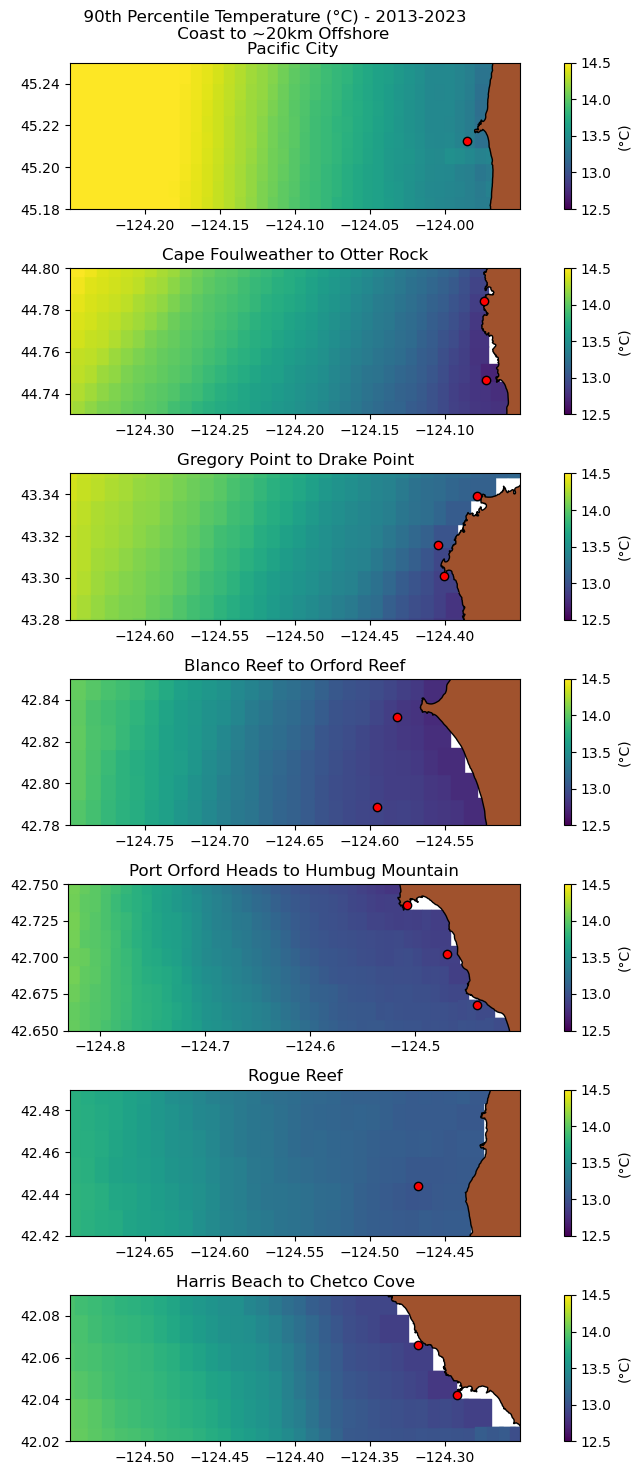

In [6]:
#Adding OR state outline, changing colors so warm colors are stressful and generally refining figure. 
fig, (ax1, ax2, ax3, ax4, ax5, ax6, ax7) = plt.subplots(7,1, figsize = (9,15))
fig.suptitle('      90th Percentile Temperature (°C) - 2013-2023\n         Coast to ~20km Offshore')
p1 = ax1.scatter(x = temp_pa_p90["lon_rho"], y = temp_pa_p90["lat_rho"], c = temp_pa_p90["surf_temp"],marker = "s", s = 130, vmin = 12.5, vmax = 14.5)
ax1.set_ylim(45.18, 45.25)
ax1.set_xlim(-124.25,-123.95)
or_land.plot(ax = ax1,facecolor = "sienna",edgecolor = "black")
ax1.scatter(x = sites.iloc[0:2,6], y = sites.iloc[0:2,5], c = "red", edgecolors = "black")
ax1.set_title("Pacific City ")
cbar1 = plt.colorbar(p1, ax = ax1)
cbar1.set_label('(°C)')
ax1.set_xticks([-124.2, -124.15,-124.1,-124.05, -124])


p2 = ax2.scatter(x = temp_fo_p90["lon_rho"], y = temp_fo_p90["lat_rho"], c = temp_fo_p90["surf_temp"],marker = "s", s = 170, vmin = 12.5, vmax = 14.5)
ax2.set_title("Cape Foulweather to Otter Rock")
ax2.set_ylim(44.73, 44.80)
ax2.set_xlim(-124.35,-124.05)
or_land.plot(ax = ax2,facecolor = "sienna",edgecolor = "black")
ax2.scatter(x = sites.iloc[2:4,6], y = sites.iloc[2:4,5], c = "red", edgecolors = "black")
cbar2 = plt.colorbar(p2, ax = ax2)
cbar2.set_label('(°C)')
ax2.set_xticks([-124.3, -124.25,-124.2,-124.15, -124.1])


p3 = ax3.scatter(x = temp_ca_p90["lon_rho"], y = temp_ca_p90["lat_rho"], c = temp_ca_p90["surf_temp"],marker = "s", s = 290, vmin = 12.5, vmax = 14.5)
cbar3 = plt.colorbar(p3, ax = ax3)
cbar3.set_label('(°C)')
ax3.set_title("Gregory Point to Drake Point")
ax3.set_ylim(43.28, 43.35)
ax3.set_xlim(-124.65,-124.35)
or_land.plot(ax = ax3,facecolor = "sienna",edgecolor = "black")
ax3.scatter(x = sites.iloc[4:7,6], y = sites.iloc[4:7,5], c = "red", edgecolors = "black")
ax3.set_xticks([-124.6, -124.55,-124.5,-124.45, -124.4])


p4 = ax4.scatter(x = temp_po_p90["lon_rho"], y = temp_po_p90["lat_rho"], c = temp_po_p90["surf_temp"],marker = "s", s = 350, vmin = 12.5, vmax = 14.5)
cbar4 = plt.colorbar(p4, ax = ax4)
cbar4.set_label('(°C)')
ax4.set_title("Blanco Reef to Orford Reef")
ax4.set_ylim(42.78,42.85)
ax4.set_xlim(-124.8,-124.5)
or_land.plot(ax = ax4,facecolor = "sienna",edgecolor = "black")
ax4.scatter(x = sites.iloc[7:12,6], y = sites.iloc[7:12,5], c = "red", edgecolors = "black")
ax4.set_xticks([-124.75, -124.7,-124.65,-124.6, -124.55])


p5 = ax5.scatter(x = temp_po_p90["lon_rho"], y = temp_po_p90["lat_rho"], c = temp_po_p90["surf_temp"],marker = "s", s = 180, vmin = 12.5, vmax = 14.5)
cbar5 = plt.colorbar(p5, ax = ax5)
cbar5.set_label('(°C)')
ax5.set_title("Port Orford Heads to Humbug Mountain")
ax5.set_ylim(42.65,42.75)
ax5.set_xlim(-124.83,-124.4)
or_land.plot(ax = ax5,facecolor = "sienna",edgecolor = "black")
ax5.scatter(x = sites.iloc[7:12,6], y = sites.iloc[7:12,5], c = "red", edgecolors = "black")
ax5.set_xticks([-124.8, -124.7,-124.6,-124.5])

p6 = ax6.scatter(x = temp_ro_p90["lon_rho"], y = temp_ro_p90["lat_rho"], c = temp_ro_p90["surf_temp"],marker = "s",s = 355, vmin = 12.5, vmax = 14.5)
ax6.set_title("Rogue Reef")
cbar6 = plt.colorbar(p6, ax = ax6)
cbar6.set_label('(°C)')
ax6.set_ylim(42.42,42.49)
ax6.set_xlim(-124.7,-124.4)
or_land.plot(ax = ax6,facecolor = "sienna",edgecolor = "black")
ax6.scatter(x = sites.iloc[12,6], y = sites.iloc[12,5], c = "red", edgecolors = "black")
ax6.set_xticks([-124.65, -124.6,-124.55,-124.5, -124.45])

p7 = ax7.scatter(x = temp_br_p90["lon_rho"], y = temp_br_p90["lat_rho"], c = temp_br_p90["surf_temp"],marker = "s", s = 400, vmin = 12.5, vmax = 14.5)
ax7.set_title("Harris Beach to Chetco Cove")
cbar7 = plt.colorbar(p7, ax = ax7)
cbar7.set_label('(°C)')
ax7.set_ylim(42.02,42.09)
ax7.set_xlim(-124.55,-124.25)
or_land.plot(ax = ax7,facecolor = "sienna",edgecolor = "black")
ax7.scatter(x = sites.iloc[13:,6], y = sites.iloc[13:,5], c = "red", edgecolors = "black")
ax7.set_xticks([-124.5, -124.45,-124.4,-124.35, -124.3])

plt.tight_layout()
plt.savefig("C:/Users/sarah/Documents/GitHub/ORKA_StatusReport_FollowupPaper/StatusReport_FollowupPaper_Figures/TempNitrateMaps/Temp_90thP_Map.jpg", dpi = 600)
plt.show()
